<a href="https://colab.research.google.com/github/JulTob/Optimization/blob/main/Practicas/Practica_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [100]:
def step_line(t):
    return max(0, min(1,t))

In [101]:
for n in range(-2,7):
    print(step_line(n/5))

0
0
0
0.2
0.4
0.6
0.8
1
1


# <font color="steelblue">**Enunciado  Práctica 3**</font>

## <font color="steelblue">**Isotonic Regression**</font>

La <b>regresión isotónica</b> es una técnica no paramétrica utilizada en estadística para ajustar un conjunto de datos/observaciones a una función no decreciente. Esta técnica es útil cuando se espera que la relación entre las variables independientes y la variable dependiente  es una relación monótona pero no lineal.

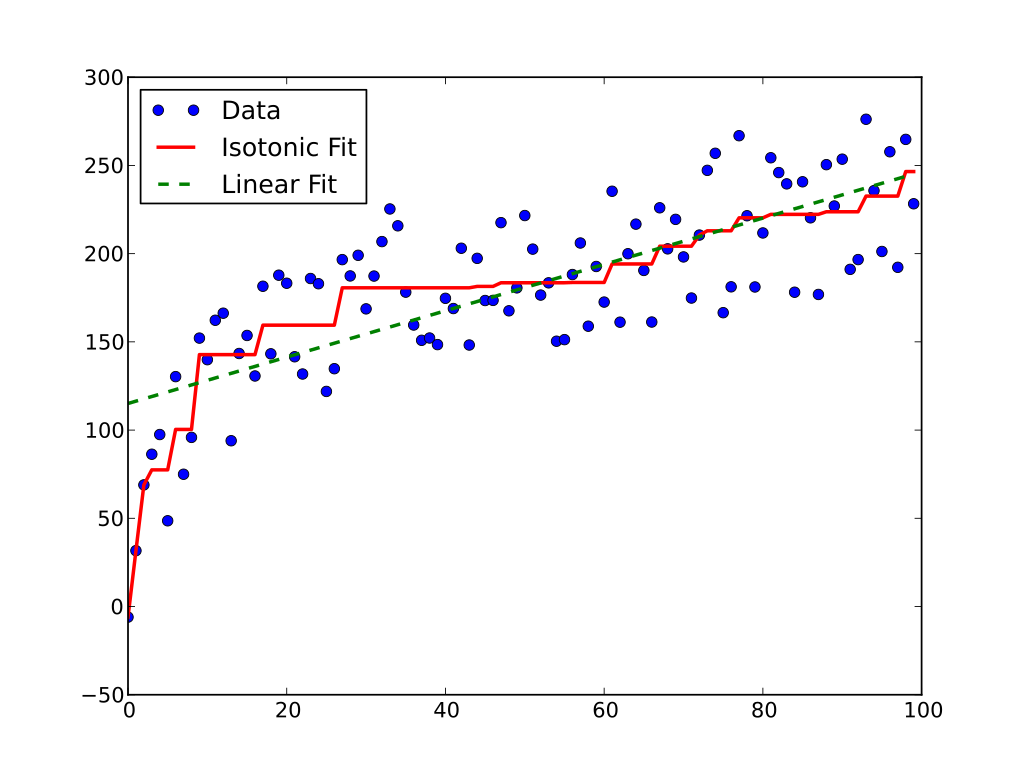

Dado un conjunto de observaciones $(x_i,y_i)$ para $i=1,\cdots,n$, la regressión isotónica puede formularse mediante un problema de optimización cuadrática del siguiente modo:

$$\min \sum_{i=1}^n \epsilon^2_i \qquad \qquad\qquad$$
$$ s.a. \qquad\qquad\qquad\qquad$$
$$  y_i=\alpha_i + \epsilon_i, \quad i=1,\cdots,n$$
$$ p_{ij} \alpha_i \leq p_{ij}\alpha_j, \quad i,j=1,\cdots,n$$
$$ \alpha_i, \, \,\epsilon_i \,\quad  \text{free} \quad i=1,\cdots,n$$

donde $P=\{p_{ij}\}$ es una matriz binaria que recoge el orden parcial de los datos observados $x_i$.

$$ p_{ij}= 1 \quad si \quad  \mathbf{x}_i \preceq \mathbf{x}_j$$
$$ p_{ij}= 0 \quad si \quad  \mathbf{x}_i \nprec \mathbf{x}_j$$

## <font color="steelblue">**Ejercicio  Práctica 3**</font>

Para cada una de las distribuciones siguientes, gererar 25 valores y calcular la regresión isotónica para esos 25 valores.
* Caso 1: Cobb-Douglas, ($x,y$):
  $$y_i=x_i^{0.5}+v_i, \quad x_i \sim U(1,6), v_i\sim N(0,\sigma_v^2)$$
* Caso 2: Logistic function, ($x,y$):
  $$y_i=\frac{1+e^7}{e^7}\frac{e^{-3+10x_i}}{1+e^{-3+10x_i}}+v_i, \quad x_i \sim U(0,1), v_i\sim N(0,\sigma_v^2)$$

Utilizar $\sigma_v= 0.1$ y $\sigma_v= 0.2$

* Realizar una representación gráfica del ajuste realizado en los casos 1 y 2.
* Calcular para cada ajuste

  $$ MSE = \dfrac{1}{n}\sum_{i}( \hat{y}_i - y_i)^2$$

* Comparar con los siguientes ajustes de regresión:
  - $ \hat{y} = \alpha + \beta x $
  - $ \hat{y} = \alpha + \beta_1 x + \beta_2 x^2 $
  - $ \hat{y} = \alpha + \beta_1 x + \beta_2 x^2 +\beta_3 x^3$
  - $ \hat{y} = \alpha x^\beta $

y otras funciones que te apetezcan

  


In [102]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cvxpy as cp
from scipy.optimize import curve_fit

# Fijar semilla para reproducibilidad
np.random.seed(42)

# 1. Generación de datos
def generar_datos_caso1(n=25, sigma=0.1):
    x = np.random.uniform(1, 6, n)
    v = np.random.normal(0, sigma, n)
    y = x**0.5 + v
    return x, y

def generar_datos_caso2(n=25, sigma=0.1):
    x = np.random.uniform(0, 1, n)
    v = np.random.normal(0, sigma, n)
    factor1 = (1 + np.exp(7)) / np.exp(7)
    factor2 = np.exp(-3 + 10*x) / (1 + np.exp(-3 + 10*x))
    y = factor1 * factor2 + v
    return x, y

In [103]:
def resolver_regresion_isotonica(x, y):
    """
    Resuelve la regresión isotónica formulada como un problema de optimización cuadrática:
    Minimizar sum (alpha_i - y_i)^2
    Sujeto a: alpha_i <= alpha_j para todo x_i <= x_j
    """
    n = len(x)
    alpha = cp.Variable(n)

    # Crear las restricciones de orden basados en los valores de x
    constraints = []
    for i in range(n):
        for j in range(n):
            if x[i] < x[j]:
                constraints.append(alpha[i] <= alpha[j])
            elif x[i] == x[j] and i != j:
                constraints.append(alpha[i] == alpha[j])

    # Función objetivo: Minimizar el error cuadrático
    objective = cp.Minimize(cp.sum_squares(alpha - y))
    prob = cp.Problem(objective, constraints)
    prob.solve()

    return alpha.value

In [104]:
# Definición de modelos para comparar
def modelo_lineal(x, a, b):
    return a + b * x

def modelo_cuadratico(x, a, b1, b2):
    return a + b1 * x + b2 * (x**2)

def modelo_cubico(x, a, b1, b2, b3):
    return a + b1 * x + b2 * (x**2) + b3 * (x**3)

def modelo_potencial(x, a, b):
    return a * (x**b)

def calcular_mse(y_true, y_pred):
    return np.mean((y_true - y_pred)**2)


In [105]:
# Ejecutar experimentos para todos los casos y sigmas
resultados = {}

casos = [
    (
        "Caso 1 (Cobb-Douglas) sigma=0.1",
        generar_datos_caso1,
        0.1,
        ),
    (
        "Caso 1 (Cobb-Douglas) sigma=0.2",
        generar_datos_caso1,
        0.2,
        ),
    (
        "Caso 2 (Logística) sigma=0.1",
        generar_datos_caso2,
        0.1,
        ),
    (
        "Caso 2 (Logística) sigma=0.2",
        generar_datos_caso2,
        0.2,
        ),
    ]



### Comparación Adicional con el Modelo Logístico (Logit)

In [106]:
def modelo_logistico(x, L, k, x0, c):
    return L / (1 + np.exp(-k * (x - x0))) + c

### Nueva Estructura de Ranking: Casos Horizontales y Regresiones Verticales

### Inclusión del Modelo Escalón Rampa Truncado

In [107]:
def modelo_escalon_rampa(x, m, c):
    # Señal rampa truncada con mínimo 0 y máximo 1
    rampa = m * (x - c)
    return np.clip(rampa, 0, 1)



In [108]:
import numpy as np
from scipy.optimize import lsq_linear


def fit_rampas(x, y, inicios, anchos, *, monotona=True):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    c = np.atleast_1d(np.asarray(inicios, dtype=float)).copy()

    if x.ndim != 1 or y.shape != x.shape or x.size == 0 or c.ndim != 1:
        raise ValueError(
            "x e y deben ser vectores no vacíos de igual longitud; "
            "inicios debe ser un vector."
        )

    try:
        h = np.broadcast_to(
            np.asarray(anchos, dtype=float), c.shape
        ).copy()
    except ValueError as error:
        raise ValueError(
            "anchos debe ser un número o un vector del tamaño de inicios."
        ) from error

    if (
        not all(np.isfinite(vector).all() for vector in (x, y, c, h))
        or np.any(h <= 0)
    ):
        raise ValueError(
            "Los datos deben ser finitos y las anchuras positivas."
        )

    def matriz(puntos):
        puntos = np.asarray(puntos, dtype=float)
        return np.clip((puntos[..., None] - c) / h, 0, 1)

    diseño = np.column_stack((np.ones(x.size), matriz(x)))
    inferiores = (
        np.r_[-np.inf, np.zeros(c.size)]
        if monotona
        else np.full(c.size + 1, -np.inf)
        )

    resultado = lsq_linear(
        diseño,
        y,
        bounds=(inferiores, np.inf),
        method="bvls",
        tol=1e-12,
    )
    if not resultado.success:
        raise RuntimeError(
            f"El ajuste no ha convergido: {resultado.message}"
        )

    base = float(resultado.x[0])
    pesos = resultado.x[1:].copy()

    def predecir(puntos):
        return base + matriz(puntos) @ pesos

    return {
        "base": base,
        "pesos": pesos,
        "inicios": c,
        "anchos": h,
        "predecir": predecir,
    }

In [109]:
def crear_modelos_rampa(x, y, *, n_rampas=6, monotona=True):
    if not isinstance(monotona, (bool, np.bool_)):
        raise TypeError("monotona debe ser True o False.")

    if (
        isinstance(n_rampas, (bool, np.bool_))
        or not isinstance(n_rampas, (int, np.integer))
        or n_rampas < 1
    ):
        raise ValueError("n_rampas debe ser un entero positivo.")

    x = np.asarray(x, dtype=float)

    if x.ndim != 1 or x.size == 0 or not np.isfinite(x).all():
        raise ValueError("x debe ser un vector no vacío de valores finitos.")

    # Una rampa entre cada par de nodos consecutivos.
    nudos = np.unique(
        np.linspace(x.min(), x.max(), n_rampas + 1)
    )

    # Rampas de anchura 1.
    # Algunos inicios quedan antes de los datos para permitir
    # que también haya transiciones que terminen dentro del dominio.
    bordes = np.linspace(x.min() - 1, x.max(), n_rampas + 1)
    inicios = (bordes[:-1] + bordes[1:]) / 2

    modo = "monótonas" if monotona else "libres"

    return {
        f"Rampas locales ({modo})": fit_rampas(
            x, y,
            inicios=nudos[:-1],
            anchos=np.diff(nudos),
            monotona=monotona,
        ),
        f"Rampas de anchura 1 ({modo})": fit_rampas(
            x, y,
            inicios=inicios,
            anchos=1.0,
            monotona=monotona,
        ),
    }

### Implementación de los Nuevos Modelos

Definiremos:
1. **Isotónica con Rampas:** Tomamos los valores óptimos $\alpha$ de la optimización cuadrática ordenados por $x$ y realizamos una interpolación lineal para evaluar cualquier punto de forma continua y monótona.
2. **Escalón con Activación Única (Rampa Infinita):** Optimizamos el umbral $c$ mediante una búsqueda en rejilla (*grid search*) para encontrar el punto de salto que minimiza el MSE.

In [110]:
def evaluar_isotonica_rampas(x_train, y_iso_train, x_eval):
    """
    Genera una función continua uniendo con segmentos lineales (rampas)
    los puntos obtenidos de la regresión isotónica tradicional.
    """
    sort_idx = np.argsort(x_train)
    x_sorted = x_train[sort_idx]
    y_sorted = y_iso_train[sort_idx]

    # Interpolación lineal unidimensional
    return np.interp(x_eval, x_sorted, y_sorted)

def ajustar_escalon_puro(x, y):
    """
    Ajusta una función escalón puro f(x) = 1 si x >= c else 0
    probando todos los umbrales de activación 'c' posibles en el rango de x.
    """
    c_candidatos = np.linspace(min(x), max(x), 200)
    mejor_c = c_candidatos[0]
    mejor_mse = float('inf')

    for c in c_candidatos:
        y_pred = np.where(x >= c, 1.0, 0.0)
        mse = np.mean((y - y_pred)**2)
        if mse < mejor_mse:
            mejor_mse = mse
            mejor_c = c

    return mejor_c

def modelo_escalon_puro(x, c):
    return np.where(x >= c, 1.0, 0.0)

### Implementación de Modelos de Rampa Paramétrica con y sin Pesos ($w$)

Definiremos e integraremos dos formulaciones de la rampa paramétrica para estudiar la ganancia del parámetro de peso $w$:
1. **Rampa con Peso y Pendiente Interna ($w$ y $m$):** $f(x) = w \cdot \max(0, \min(m(x-c), 1))$
2. **Rampa Monótona Simple ($m$):** $f(x) = m \cdot \max(0, \min(x-c, 1))$

In [111]:
def modelo_rampa_con_w(x, w, m, c):
    # w * step_incl(m * (x - c))
    return w * np.clip(m * (x - c), 0, 1)

def modelo_rampa_sin_w(x, m, c):
    # m * step_incl(x - c)
    return m * np.clip(x - c, 0, 1)

def ajustar_modelos_rampa_paramétrica(x, y):
    # Se eliminan los límites de monotonicidad forzada (bounds=[0.0, ...])
    # para permitir que w, m y c exploren todo el espacio real (negativos y positivos).
    try:
        # p0: w=1.0, m=2.0, c=min(x)
        popt_con_w, _ = curve_fit(modelo_rampa_con_w, x, y, p0=[1.0, 2.0, float(np.min(x))],
                                  maxfev=15000)
    except:
        popt_con_w = None

    try:
        # p0: m=2.0, c=min(x)
        popt_sin_w, _ = curve_fit(modelo_rampa_sin_w, x, y, p0=[2.0, float(np.min(x))],
                                  maxfev=15000)
    except:
        popt_sin_w = None

    return popt_con_w, popt_sin_w

In [112]:
def evaluar_y_comparar_rampas_pesos(x, y, nombre_caso):
    # Obtener ajustes de los nuevos modelos de rampa
    popt_con_w, popt_sin_w = ajustar_modelos_rampa_paramétrica(x, y)

    # Ajustar también la regresión isotónica tradicional para referencia
    y_iso = resolver_regresion_isotonica(x, y)

    y_pred_con_w = modelo_rampa_con_w(x, *popt_con_w) if popt_con_w is not None else np.nan * np.ones_like(y)
    y_pred_sin_w = modelo_rampa_sin_w(x, *popt_sin_w) if popt_sin_w is not None else np.nan * np.ones_like(y)

    # Calcular MSEs
    mse_con_w = calcular_mse(y, y_pred_con_w)
    mse_sin_w = calcular_mse(y, y_pred_sin_w)
    mse_iso = calcular_mse(y, y_iso)

    # Visualización detallada de ambas rampas
    x_grid = np.linspace(min(x), max(x), 300)

    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, color='black', label='Datos Observados', zorder=5)

    sort_idx = np.argsort(x)
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', alpha=0.4, linestyle='--', label='Isotónica (QP)')

    if popt_con_w is not None:
        plt.plot(x_grid, modelo_rampa_con_w(x_grid, *popt_con_w), 'blue', linewidth=2, label=f'Rampa con w (MSE={mse_con_w:.4f})')
    if popt_sin_w is not None:
        plt.plot(x_grid, modelo_rampa_sin_w(x_grid, *popt_sin_w), 'green', linewidth=2, label=f'Rampa sin w (MSE={mse_sin_w:.4f})')

    plt.title(f'Comparación de Formulaciones de Rampa - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

    return {
        'Rampa con Peso (w)': mse_con_w,
        'Rampa sin Peso': mse_sin_w,
        'Isotónica (QP)': mse_iso
    }

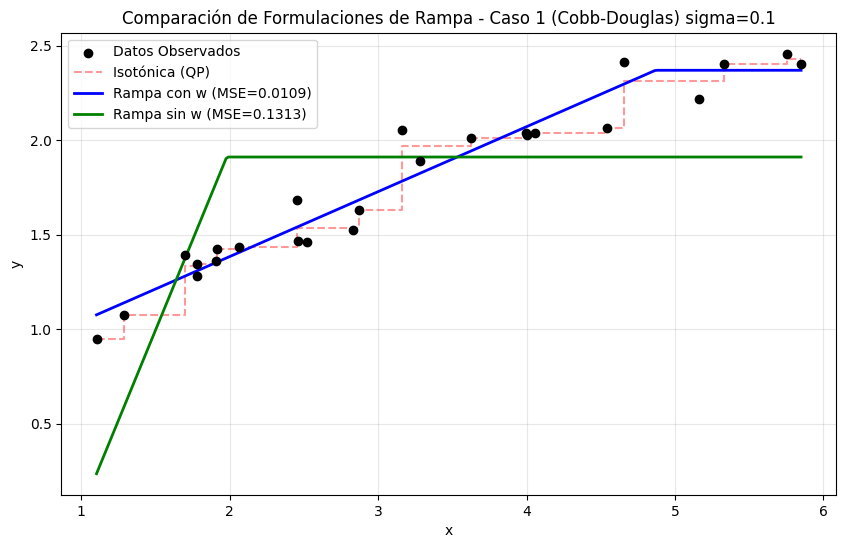

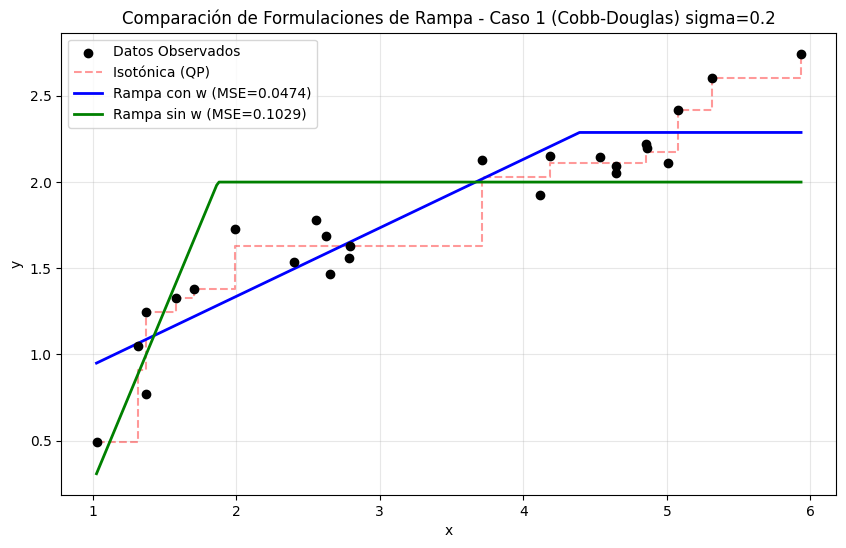

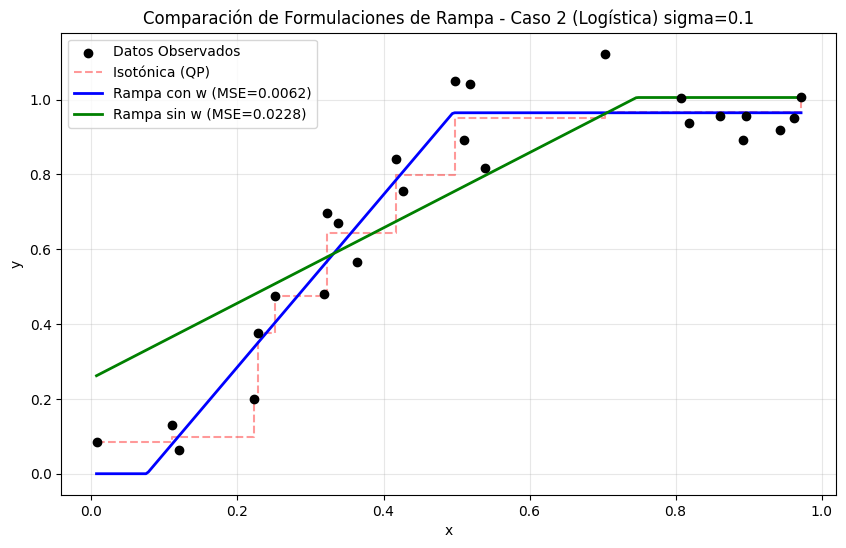

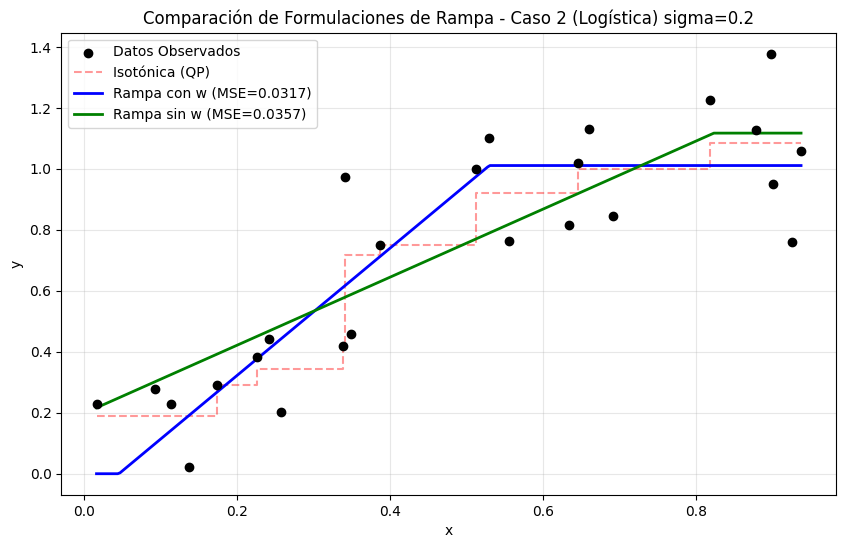

Tabla Comparativa de MSE:


,Rampa con Peso (w),Rampa sin Peso,Isotónica (QP)
Caso 1 (Cobb-Douglas) sigma=0.1,0.010935,0.131257,0.002945
Caso 1 (Cobb-Douglas) sigma=0.2,0.047386,0.102947,0.005875
Caso 2 (Logística) sigma=0.1,0.006168,0.022774,0.003577
Caso 2 (Logística) sigma=0.2,0.031716,0.035746,0.022080



Tabla de Rankings de Modelos de Rampa (Menor Ranking es mejor):


,Caso 1 (Cobb-Douglas) sigma=0.1,Caso 1 (Cobb-Douglas) sigma=0.2,Caso 2 (Logística) sigma=0.1,Caso 2 (Logística) sigma=0.2,Ranking Medio
Isotónica (QP),1.0,1.0,1.0,1.0,1.0
Rampa con Peso (w),2.0,2.0,2.0,2.0,2.0
Rampa sin Peso,3.0,3.0,3.0,3.0,3.0


In [113]:
resultados_rampas = {}
for nombre, generador, sigma in casos:
    x_c, y_c = generador(n=25, sigma=sigma)
    res = evaluar_y_comparar_rampas_pesos(x_c, y_c, nombre)
    resultados_rampas[nombre] = res

# Generar tabla de comparación y rankings
df_res_rampas = pd.DataFrame(resultados_rampas).T
df_ranking_rampas = df_res_rampas.rank(axis=1, ascending=True).T
df_ranking_rampas['Ranking Medio'] = df_ranking_rampas.mean(axis=1)

print("Tabla Comparativa de MSE:")
display(df_res_rampas)

print("\nTabla de Rankings de Modelos de Rampa (Menor Ranking es mejor):")
display(df_ranking_rampas.sort_values(by='Ranking Medio'))

### Evaluación y Comparativa Final Consolidada de Todos los Modelos

En este bloque unificaremos todos los modelos desarrollados en la práctica para realizar una comparativa integral:
* **Isotónica Estándar (QP)**
* **Isotónica con Rampas Dinámicas (Tramos continuos)**
* **Rampas Apiladas (Monotone Pursuit - Greedy)**
* **Rampa Paramétrica Completa (con Peso $w$)**
* **Rampa Paramétrica Simple (sin Peso $w$)**
* **Modelos Polinómicos (Lineal, Cuadrático, Cúbico)**
* **Modelo Potencial**
* **Modelo Logístico (Logit)**
* **Escalón Rampa Truncado**
* **Escalón Puro (Activación)**

### Evaluación Completa de Todos los Escenarios

Incorporamos las nuevas variantes a la rutina de cálculo y generamos los gráficos comparativos correspondientes.

In [114]:
def fijar_parametros(funcion, parametros):
    parametros = tuple(parametros)

    def predecir(puntos):
        return funcion(np.asarray(puntos, dtype=float), *parametros)

    return predecir


def evaluar_predicciones(modelos, x, y):
    errores = {}

    for nombre, predecir in modelos.items():
        predicciones = np.asarray(predecir(x), dtype=float)

        if (
            predicciones.shape != np.shape(y)
            or not np.isfinite(predicciones).all()
        ):
            raise ValueError(f"Predicciones inválidas en {nombre}.")

        errores[nombre] = calcular_mse(y, predicciones)

    return errores

In [115]:
def ajustar_y_evaluar_todos_los_modelos(
        x, y, nombre_caso, *,
        monotona=True,
        n_rampas=6,
        devolver_modelos=False,
        ):

    # 1. Regresión Isotónica Estándar (QP)
    y_iso = resolver_regresion_isotonica(x, y)

    # 2. Regresión Isotónica con Rampas (Interpolada)
    # Evaluamos en los mismos puntos x para el cálculo del MSE de entrenamiento
    y_iso_rampas = evaluar_isotonica_rampas(x, y_iso, x)

    # Ajustes paramétricos tradicionales
    popt_lin, _ = curve_fit(modelo_lineal, x, y)
    popt_quad, _ = curve_fit(modelo_cuadratico, x, y)
    popt_cub, _ = curve_fit(modelo_cubico, x, y)

    try:
        popt_pot, _ = curve_fit(modelo_potencial, x, y, p0=[1, 1], maxfev=5000)
        y_pot = modelo_potencial(x, *popt_pot)
    except:
        y_pot = np.nan * np.ones_like(y)

    try:
        popt_log, _ = curve_fit(modelo_logistico, x, y, p0=[1, 10, 0.5, 0], maxfev=10000)
        y_log = modelo_logistico(x, *popt_log)
    except:
        y_log = np.nan * np.ones_like(y)

    # Escalón Rampa (Paramétrico anterior)
    try:
        popt_rampa, _ = curve_fit(modelo_escalon_rampa, x, y, p0=[2.0, 0.2], maxfev=10000)
        y_rampa = modelo_escalon_rampa(x, *popt_rampa)
    except:
        y_rampa = np.nan * np.ones_like(y)

    # 3. Escalón Puro (Activación Única / Rampa Infinita)
    c_optimo = ajustar_escalon_puro(x, y)
    y_escalon_puro = modelo_escalon_puro(x, c_optimo)

    y_lin = modelo_lineal(x, *popt_lin)
    y_quad = modelo_cuadratico(x, *popt_quad)
    y_cub = modelo_cubico(x, *popt_cub)

    # Calcular MSEs reales evaluados contra la observación original (y)
    mses = {
        'Isotónica (QP)': calcular_mse(y, y_iso),
        'Isotónica c/ Rampas': calcular_mse(y, y_iso_rampas),
        'Lineal': calcular_mse(y, y_lin),
        'Cuadrática': calcular_mse(y, y_quad),
        'Cúbica': calcular_mse(y, y_cub),
        'Potencial': calcular_mse(y, y_pot) if not np.isnan(y_pot[0]) else np.nan,
        'Logístico (Logit)': calcular_mse(y, y_log) if not np.isnan(y_log[0]) else np.nan,
        'Escalón Rampa': calcular_mse(y, y_rampa) if not np.isnan(y_rampa[0]) else np.nan,
        'Escalón Puro': calcular_mse(y, y_escalon_puro)
    }

    rampas = crear_modelos_rampa(
        x, y,
        n_rampas=n_rampas,
        monotona=monotona,
        )

    mses.update({
        nombre: calcular_mse(y, modelo["predecir"](x))
        for nombre, modelo in rampas.items()
        })
    # Representación Gráfica
    x_grid = np.linspace(min(x), max(x), 300)
    sort_idx = np.argsort(x)

    plt.figure(figsize=(11, 7))
    plt.scatter(x, y, color='black', zorder=5, label='Datos Observados')

    # Comparativa Isotónicas
    plt.step(x[sort_idx], y_iso[sort_idx], where='post', color='red', linewidth=2.5, label='Isotónica (Escalones QP)')
    plt.plot(x_grid, evaluar_isotonica_rampas(x, y_iso, x_grid), 'g-', linewidth=2, label='Isotónica c/ Rampas (Interpolada)')

    # Otros Modelos Seleccionados para claridad visual
    plt.plot(x_grid, modelo_cubico(x_grid, *popt_cub), 'y--', label='Cúbica')
    if not np.isnan(y_log[0]):
        plt.plot(x_grid, modelo_logistico(x_grid, *popt_log), 'c--', label='Logístico (Logit)')
    plt.plot(x_grid, modelo_escalon_puro(x_grid, c_optimo), 'm-.', linewidth=2, label=f'Escalón Puro (c={c_optimo:.2f})')

    for nombre, modelo in rampas.items():
        plt.plot(
            x_grid,
            modelo["predecir"](x_grid),
            linewidth=2,
            label=nombre,
            )

    plt.title(f'Comparación de Modelos - {nombre_caso}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    if not devolver_modelos:
        return mses

    if not np.isfinite(list(mses.values())).all():
        raise RuntimeError(
            "Hay ajustes fallidos; revísalos antes de predecir."
        )

    # Guardar los nodos y valores del ajuste isotónico.
    # Si hay x repetidos, sus valores ajustados se agrupan.
    x_iso, grupos, frecuencias = np.unique(
        x, return_inverse=True, return_counts=True
    )
    niveles = np.bincount(grupos, weights=y_iso) / frecuencias

    def predecir_escalones(puntos):
        posiciones = np.searchsorted(
            x_iso, puntos, side="right"
        ) - 1

        return niveles[
            np.clip(posiciones, 0, len(niveles) - 1)
        ]

    modelos = {
        "Isotónica (QP)": predecir_escalones,
        "Isotónica c/ Rampas": (
            lambda puntos: np.interp(puntos, x_iso, niveles)
        ),
    }

    # Guardar cada función con sus parámetros ya estimados.
    for nombre, funcion, parametros in [
        ("Lineal", modelo_lineal, popt_lin),
        ("Cuadrática", modelo_cuadratico, popt_quad),
        ("Cúbica", modelo_cubico, popt_cub),
        ("Potencial", modelo_potencial, popt_pot),
        ("Logístico (Logit)", modelo_logistico, popt_log),
        ("Escalón Rampa", modelo_escalon_rampa, popt_rampa),
        ("Escalón Puro", modelo_escalon_puro, (c_optimo,)),
    ]:
        modelos[nombre] = fijar_parametros(
            funcion, parametros
        )

    # Las nuevas rampas ya contienen su predictor.
    modelos.update({
        nombre: modelo["predecir"]
        for nombre, modelo in rampas.items()
    })

    return mses, modelos

### Tabla de Resultados Finales: Rankings y MSEs Promedio

Para facilitar una comparación cuantitativa directa, calculamos y añadimos tanto el ranking promedio como el valor del Error Cuadrático Medio (MSE) promedio de cada modelo a través de todos los escenarios simulados.

In [116]:
import numpy as np
from scipy.optimize import lsq_linear


def ajustar_rampas(x, y, inicios, anchos, *, monotona=True):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    c = np.atleast_1d(np.asarray(inicios, dtype=float)).copy()

    if x.ndim != 1 or y.shape != x.shape or x.size == 0 or c.ndim != 1:
        raise ValueError(
            "x e y deben ser vectores no vacíos de igual longitud; "
            "inicios debe ser un vector."
        )

    try:
        h = np.broadcast_to(
            np.asarray(anchos, dtype=float), c.shape
        ).copy()
    except ValueError as error:
        raise ValueError(
            "anchos debe ser un número o un vector del tamaño de inicios."
        ) from error

    if (
        not all(np.isfinite(vector).all() for vector in (x, y, c, h))
        or np.any(h <= 0)
    ):
        raise ValueError(
            "Los datos deben ser finitos y las anchuras positivas."
        )

    def matriz_rampas(puntos):
        puntos = np.asarray(puntos, dtype=float)
        return np.clip((puntos[..., None] - c) / h, 0, 1)

    diseño = np.column_stack((np.ones(x.size), matriz_rampas(x)))

    inferiores = (
        np.r_[-np.inf, np.zeros(c.size)]
        if monotona
        else np.full(c.size + 1, -np.inf)
    )

    resultado = lsq_linear(
        diseño,
        y,
        bounds=(inferiores, np.inf),
        method="bvls",
        tol=1e-12,
        max_iter=2000,
    )

    if not resultado.success:
        raise RuntimeError(
            f"El ajuste no ha convergido: {resultado.message}"
        )

    base = float(resultado.x[0])
    pesos = resultado.x[1:].copy()

    def predecir(puntos):
        return base + matriz_rampas(puntos) @ pesos

    return {
        "base": base,
        "pesos": pesos,
        "inicios": c,
        "anchos": h,
        "predecir": predecir,
    }

In [117]:
# A. Seis transiciones locales entre siete nodos.
nudos = np.linspace(np.min(x), np.max(x), 7)

rampas_locales = ajustar_rampas(
    x, y,
    inicios=nudos[:-1],
    anchos=np.diff(nudos),
)

# B. Seis transiciones con anchura 1.
bordes = np.linspace(np.min(x) - 1, np.max(x), 7)
inicios = (bordes[:-1] + bordes[1:]) / 2

rampas_anchura_uno = ajustar_rampas(
    x, y,
    inicios=inicios,
    anchos=1.0,
)

modelos_rampa = {
    "6 rampas locales": rampas_locales,
    "6 rampas de anchura 1": rampas_anchura_uno,
}

NameError: name 'x' is not defined

In [ ]:
for nombre, modelo in modelos_rampa.items():
    predicciones = modelo["predecir"](x)
    mses[nombre] = calcular_mse(y, predicciones)

In [ ]:
[(nombre, len(x)) for nombre, (x, y) in datos_casos.items()]

In [ ]:
nudos = np.unique(x)

isotonica_en_rampas = ajustar_rampas(
    x, y,
    inicios=nudos[:-1],
    anchos=np.diff(nudos),
)

In [ ]:
MONOTONA = True
# MONOTONA = False
N_RAMPAS = 6

resultados_totales = {}

for nombre, (x_c, y_c) in datos_casos.items():
    resultados_totales[nombre] = ajustar_y_evaluar(
        x_c,
        y_c,
        nombre,
        monotona=MONOTONA,
        n_rampas=N_RAMPAS,
    )

# Filas: escenarios. Columnas: modelos.
df_resultados_totales = pd.DataFrame(resultados_totales).T

# Un ajuste fallido no debe desaparecer silenciosamente del promedio.
if not np.isfinite(df_resultados_totales.to_numpy()).all():
    display(df_resultados_totales)
    raise RuntimeError(
        "Algún modelo produjo un MSE no finito. "
        "Revisa ese ajuste antes de construir el ranking."
    )

# El redondeo evita romper empates por diferencias numéricas diminutas
# en la escala de esta práctica.
df_ranking_definitivo = (
    df_resultados_totales
    .round(10)
    .rank(axis=1, ascending=True, method="average")
    .T
)

tabla_consolidada = df_ranking_definitivo.assign(
    **{
        "Ranking Medio": df_ranking_definitivo.mean(axis=1),
        "MSE entrenamiento": df_resultados_totales.mean(axis=0),
    }
).sort_values("Ranking Medio")

print("Ranking por MSE de entrenamiento")
display(tabla_consolidada)

In [ ]:
def señal_logistica(x):
    return (1 + np.exp(-7)) / (1 + np.exp(3 - 10 * x))


señales = {
    generar_datos_caso1: np.sqrt,
    generar_datos_caso2: señal_logistica,
}

SEMILLA_PRUEBA = 12345
N_PRUEBA = 2000

rng_prueba = np.random.default_rng(SEMILLA_PRUEBA)

datos_prueba = {}

for nombre, generador, sigma in casos:
    x_entrenamiento, _ = datos_casos[nombre]

    # Nuevas posiciones dentro del intervalo observado.
    x_prueba = rng_prueba.uniform(
        np.min(x_entrenamiento),
        np.max(x_entrenamiento),
        size=N_PRUEBA,
    )

    # Señal verdadera y nuevas observaciones con ruido.
    y_señal = señales[generador](x_prueba)

    y_prueba = y_señal + rng_prueba.normal(
        0,
        sigma,
        size=N_PRUEBA,
    )

    datos_prueba[nombre] = (
        x_prueba,
        y_prueba,
        y_señal,
    )

In [ ]:
resultados_prueba = {
    nombre: evaluar_predicciones(
        modelos_por_caso[nombre],
        x_prueba,
        y_prueba,
    )
    for nombre, (x_prueba, y_prueba, _) in datos_prueba.items()
}

df_mse_prueba = pd.DataFrame(resultados_prueba).T

rangos_prueba = (
    df_mse_prueba
    .round(10)
    .rank(
        axis=1,
        ascending=True,
        method="average",
    )
)

tabla_prueba = rangos_prueba.T.assign(
    **{
        "Ranking Medio": rangos_prueba.mean(axis=0),
        "MSE prueba": df_mse_prueba.mean(axis=0),
    }
).sort_values("Ranking Medio")

print("Ranking de predicción: datos nuevos")
display(tabla_prueba)

In [ ]:
rangos_entrenamiento = (
    df_resultados_totales
    .round(10)
    .rank(
        axis=1,
        ascending=True,
        method="average",
    )
)

comparacion = pd.DataFrame({
    "Rango entrenamiento": rangos_entrenamiento.mean(axis=0),
    "Rango prueba": rangos_prueba.mean(axis=0),
    "MSE entrenamiento": df_resultados_totales.mean(axis=0),
    "MSE prueba": df_mse_prueba.mean(axis=0),
})

comparacion["Mejora de rango"] = (
    comparacion["Rango entrenamiento"]
    - comparacion["Rango prueba"]
)

display(
    comparacion.sort_values("Rango prueba")
)

In [ ]:
MONOTONA = True
N_RAMPAS = 6

resultados_totales = {}
modelos_por_caso = {}

for nombre, (x_c, y_c) in datos_casos.items():
    errores, modelos = ajustar_y_evaluar_todos_los_modelos(
        x_c,
        y_c,
        nombre,
        monotona=MONOTONA,
        n_rampas=N_RAMPAS,
        devolver_modelos=True,
    )

    resultados_totales[nombre] = errores
    modelos_por_caso[nombre] = modelos

df_resultados_totales = pd.DataFrame(resultados_totales).T

/tmp/ipykernel_26019/2820886574.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c


Ranking por error de ENTRENAMIENTO (lo que hacía el cuaderno):


,Caso 1 σ=0.1,Caso 1 σ=0.2,Caso 2 σ=0.1,Caso 2 σ=0.2,Ranking Medio,MSE Medio
Isotónica (QP),1.5,1.0,1.5,1.5,1.375,0.008619
Isotónica de rampas (nudos),1.5,2.0,1.5,1.5,1.625,0.008619
Isotónica de rampas (multiescala),3.0,3.0,3.0,3.0,3.000,0.012022
Cúbica,4.0,4.0,5.0,5.0,4.500,0.017449
Logístico,6.0,6.0,4.0,4.0,5.000,0.019038
Cuadrática,5.0,7.0,6.0,6.0,6.000,0.021664
Potencial,7.0,5.0,7.0,7.0,6.500,0.025620
Lineal,8.0,8.0,8.0,8.0,8.000,0.030337


Ranking por error frente a la FUNCIÓN REAL (el criterio honesto):


,Caso 1 σ=0.1,Caso 1 σ=0.2,Caso 2 σ=0.1,Caso 2 σ=0.2,Ranking Medio,MSE Medio
Logístico,2.0,3.0,1.0,1.0,1.75,0.002736
Cuadrática,4.0,2.0,5.0,2.0,3.25,0.003395
Potencial,1.0,1.0,7.0,7.0,4.00,0.007029
Isotónica de rampas (multiescala),6.0,6.0,2.0,3.0,4.25,0.009104
Cúbica,3.0,5.0,4.0,5.0,4.25,0.006080
Isotónica de rampas (nudos),7.0,7.0,3.0,4.0,5.25,0.010356
Lineal,5.0,4.0,8.0,8.0,6.25,0.011054
Isotónica (QP),8.0,8.0,6.0,6.0,7.00,0.014378


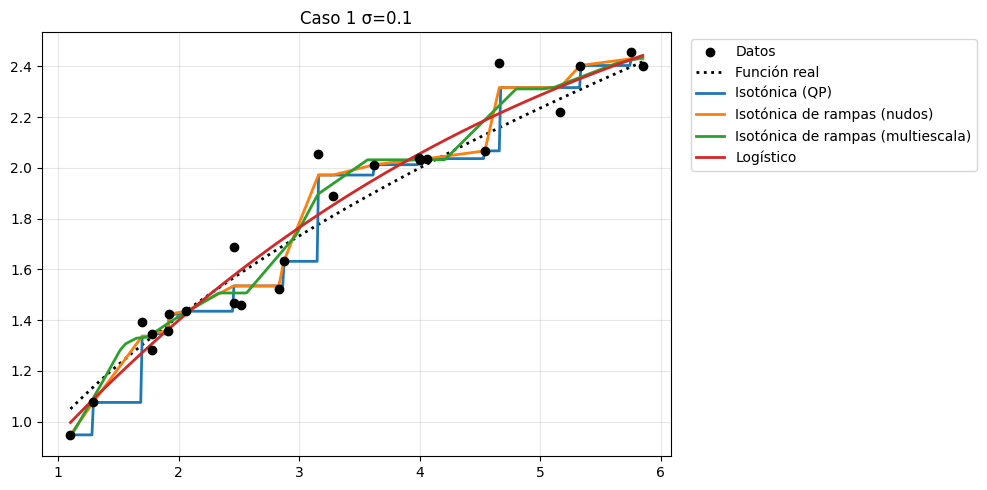

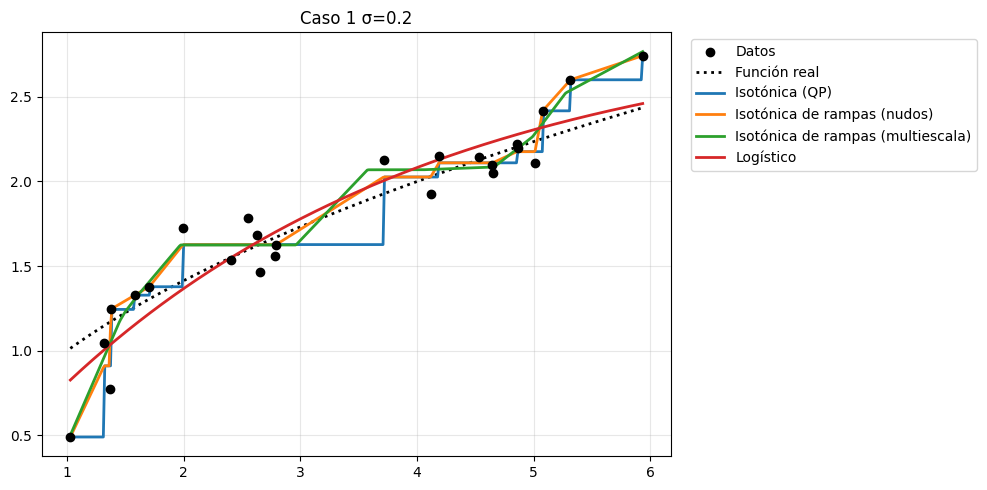

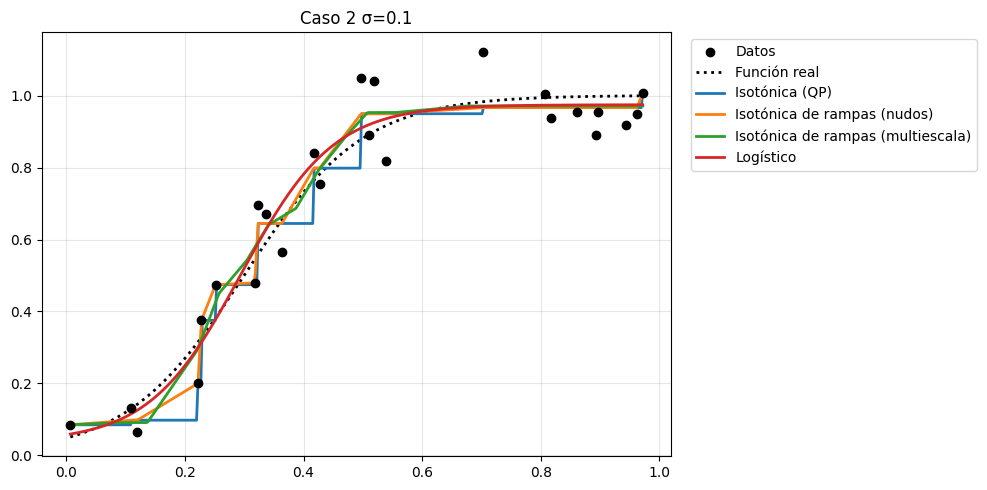

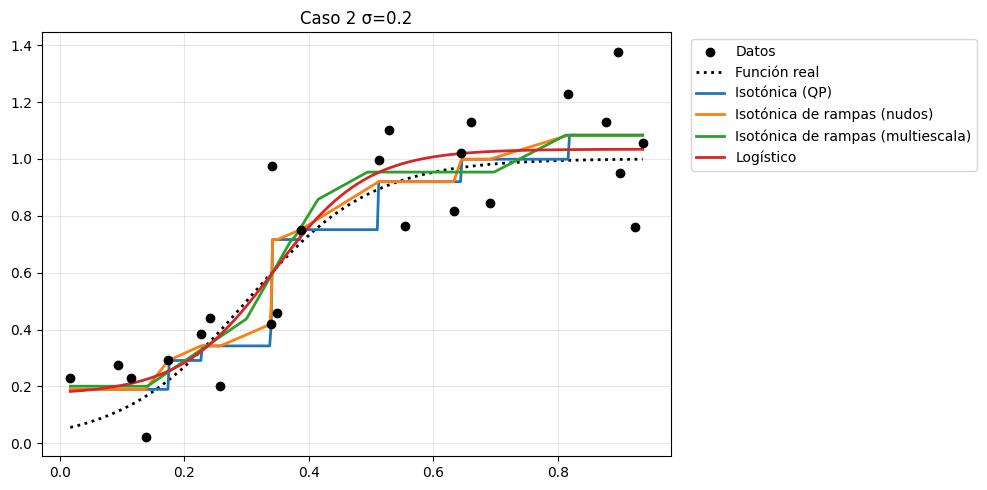

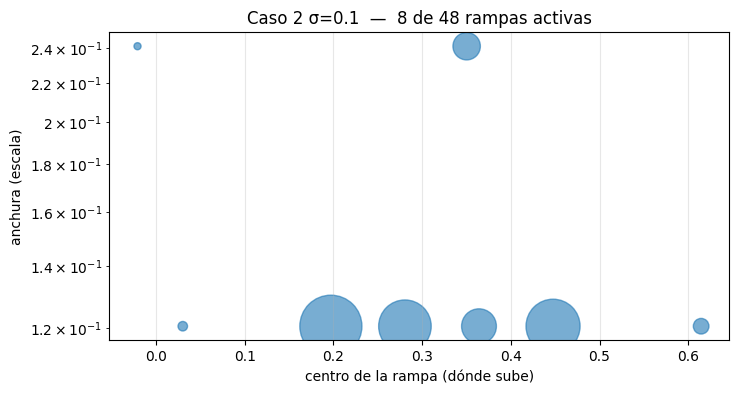

In [118]:
#-- ===================================================================
#-- Isotónica de rampas: una "serie" de rampas truncadas
#-- ===================================================================
#-- Cada bloque "# %%" es una celda. Pégalas al final de Practica_3,
#-- en orden. Reutiliza lo que ya existe en el cuaderno:
#--     generar_datos_caso1, generar_datos_caso2,
#--     resolver_regresion_isotonica,
#--     modelo_lineal, modelo_cuadratico, modelo_cubico,
#--     modelo_potencial, modelo_logistico.
#--
#-- Capas, de abajo a arriba:
#--     1. La pieza base       -> rampa(t)
#--     2. El diccionario      -> qué rampas existen (inicio, anchura)
#--     3. El ajuste           -> cuánto pesa cada rampa (pesos >= 0)
#--     4. El espectro         -> dibujar qué rampas se han usado
#--     5. El banco de pruebas -> mismos datos para todos, ranking justo


# %% Celda 1 — La pieza base (primer principio)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dataclasses import dataclass
from scipy.optimize import curve_fit
from scipy.optimize import lsq_linear


def rampa(
        t,
        ):
    """Señal t truncada: 0 si t < 0, t si 0 <= t <= 1, 1 si t > 1."""
    valores = np.asarray(t, dtype=float)
    return np.clip(valores, 0.0, 1.0)
    #-- Es tu step_line, pero trabaja con vectores enteros a la vez.


# %% Celda 2 — El diccionario de rampas (qué piezas hay disponibles)
@dataclass
class Diccionario:
    """Lista de rampas. La rampa k, evaluada en x, vale:
            rampa( (x - inicio_k) / ancho_k )
    Sube de 0 a 1 entre inicio_k e inicio_k + ancho_k."""

    inicios: np.ndarray
    anchos: np.ndarray

    def __post_init__(
            self,
            ):
        self.inicios = np.atleast_1d(np.asarray(self.inicios, dtype=float))
        self.anchos = np.atleast_1d(np.asarray(self.anchos, dtype=float))
        comprobar_diccionario(self.inicios, self.anchos)

    def __len__(
            self,
            ):
        return self.inicios.size

    def __add__(
            self,
            otro,
            ):
        """Unir dos diccionarios: todas las rampas de ambos."""
        inicios = np.concatenate((self.inicios, otro.inicios))
        anchos = np.concatenate((self.anchos, otro.anchos))
        return Diccionario(inicios, anchos)
        #-- Esto es el "álgebra": puedes escribir  grueso + fino.

    def evaluar(
            self,
            x,
            ):
        """Matriz (puntos x rampas): columna k = rampa k en cada punto."""
        puntos = np.asarray(x, dtype=float).reshape(-1, 1)
        distancia = puntos - self.inicios.reshape(1, -1)
        return rampa(distancia / self.anchos.reshape(1, -1))


def comprobar_diccionario(
        inicios,
        anchos,
        ):
    if inicios.ndim != 1 or inicios.shape != anchos.shape:
        raise ValueError("inicios y anchos deben ser vectores del mismo tamaño.")
    if inicios.size == 0:
        raise ValueError("El diccionario no puede estar vacío.")
    if not np.all(np.isfinite(inicios)) or not np.all(np.isfinite(anchos)):
        raise ValueError("inicios y anchos deben ser números finitos.")
    if np.any(anchos <= 0):
        raise ValueError("Todas las anchuras deben ser positivas.")


def diccionario_por_nudos(
        nudos,
        ):
    """Una rampa entre cada par de nudos consecutivos (una sola escala local)."""
    nudos_ordenados = np.unique(np.asarray(nudos, dtype=float))
    if nudos_ordenados.size < 2:
        raise ValueError("Hacen falta al menos dos nudos distintos.")
    return Diccionario(
        inicios=nudos_ordenados[:-1],
        anchos=np.diff(nudos_ordenados),
        )


def diccionario_de_una_escala(
        x,
        ancho,
        cantidad,
        ):
    """'cantidad' rampas de la misma anchura, repartidas por el rango de x."""
    x_min = float(np.min(x))
    x_max = float(np.max(x))
    posiciones = np.linspace(x_min - ancho, x_max, cantidad + 2)
    inicios = posiciones[1:-1]
    #-- Quitamos los extremos: una rampa que ya vale 1 en todos los datos
    #-- (o 0 en todos) no aporta nada que no aporte la constante base.
    anchos = np.full(cantidad, float(ancho))
    return Diccionario(inicios, anchos)


def diccionario_multiescala(
        x,
        fracciones=(1.0, 0.5, 0.25, 0.125),
        cantidad_por_escala=12,
        ):
    """Rampas anchas (tendencia general) + rampas estrechas (detalle).
    Es la idea de 'frecuencias' del Fourier, pero con anchuras."""
    rango = float(np.max(x) - np.min(x))
    if rango <= 0:
        raise ValueError("x debe tener al menos dos valores distintos.")

    escalas = [
        diccionario_de_una_escala(x, fraccion * rango, cantidad_por_escala)
        for fraccion in fracciones
        ]

    resultado = escalas[0]
    for escala in escalas[1:]:
        resultado = resultado + escala
    return resultado


# %% Celda 3 — El ajuste: cuánto pesa cada rampa
@dataclass
class ModeloRampas:
    """f(x) = base + suma_k  peso_k * rampa_k(x),   con peso_k >= 0."""

    base: float
    pesos: np.ndarray
    diccionario: Diccionario

    def __call__(
            self,
            x,
            ):
        return self.base + self.diccionario.evaluar(x) @ self.pesos
        #-- Un modelo se usa como una función:  modelo(x_nuevos)

    def rampas_activas(
            self,
            umbral=1e-9,
            ):
        return self.pesos > umbral


def comprobar_datos(
        x,
        y,
        ):
    if x.ndim != 1 or y.shape != x.shape or x.size == 0:
        raise ValueError("x e y deben ser vectores no vacíos del mismo tamaño.")
    if not np.all(np.isfinite(x)) or not np.all(np.isfinite(y)):
        raise ValueError("x e y deben contener solo números finitos.")


def ajustar_isotonica_rampas(
        x,
        y,
        diccionario,
        suavizado=0.0,
        ):
    """Mínimos cuadrados con pesos >= 0.
    Pesos >= 0  ->  cada rampa solo puede SUBIR  ->  f es no decreciente.
    suavizado > 0 penaliza pesos grandes (frena el sobreajuste)."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    comprobar_datos(x, y)
    if suavizado < 0:
        raise ValueError("suavizado no puede ser negativo.")

    columna_base = np.ones((x.size, 1))
    matriz = np.hstack((columna_base, diccionario.evaluar(x)))
    objetivo = y.copy()

    if suavizado > 0:
        filas_penalizacion = np.hstack((
            np.zeros((len(diccionario), 1)),
            np.sqrt(suavizado) * np.eye(len(diccionario)),
            ))
        #-- Añadir la fila  sqrt(s)*peso_k = 0  equivale a sumar
        #-- s * peso_k^2  al error. La base no se penaliza.
        matriz = np.vstack((matriz, filas_penalizacion))
        objetivo = np.concatenate((objetivo, np.zeros(len(diccionario))))

    limite_inferior = np.concatenate(([-np.inf], np.zeros(len(diccionario))))
    limite_superior = np.full(len(diccionario) + 1, np.inf)

    resultado = lsq_linear(
        matriz,
        objetivo,
        bounds=(limite_inferior, limite_superior),
        method="bvls",
        tol=1e-12,
        )
    if not resultado.success:
        raise RuntimeError(f"El ajuste de rampas no convergió: {resultado.message}")

    return ModeloRampas(
        base=float(resultado.x[0]),
        pesos=resultado.x[1:].copy(),
        diccionario=diccionario,
        )


# %% Celda 4 — El espectro: qué rampas ha elegido el ajuste
def dibujar_espectro(
        modelo,
        titulo="Espectro de rampas",
        ):
    """Eje x: centro de la rampa. Eje y: anchura (escala).
    Tamaño del punto: peso. Equivale al espectro de una FFT."""
    activas = modelo.rampas_activas()
    if not np.any(activas):
        print("Ninguna rampa activa: el modelo es una constante.")
        return

    inicios = modelo.diccionario.inicios[activas]
    anchos = modelo.diccionario.anchos[activas]
    pesos = modelo.pesos[activas]
    centros = inicios + anchos / 2

    plt.figure(figsize=(8, 4))
    plt.scatter(
        centros,
        anchos,
        s=2000 * pesos / pesos.max(),
        alpha=0.6,
        )
    plt.yscale("log")
    plt.xlabel("centro de la rampa (dónde sube)")
    plt.ylabel("anchura (escala)")
    plt.title(f"{titulo}  —  {activas.sum()} de {len(activas)} rampas activas")
    plt.grid(True, alpha=0.3)
    plt.show()


# %% Celda 5 — Banco de pruebas: mismos datos, mismo criterio, para todos
@dataclass
class Escenario:
    nombre: str
    x: np.ndarray
    y: np.ndarray
    verdad: object
    #-- La función real sin ruido. La conocemos porque simulamos los datos.


def verdad_caso1(
        x,
        ):
    return np.sqrt(x)


def verdad_caso2(
        x,
        ):
    exponente = -3 + 10 * np.asarray(x, dtype=float)
    factor = (1 + np.exp(7)) / np.exp(7)
    return factor * np.exp(exponente) / (1 + np.exp(exponente))


def crear_escenarios(
        semilla=42,
        n=25,
        ):
    """Generar los datos UNA sola vez. Todos los modelos usan los mismos."""
    np.random.seed(semilla)
    definiciones = [
        ("Caso 1 σ=0.1", generar_datos_caso1, verdad_caso1, 0.1),
        ("Caso 1 σ=0.2", generar_datos_caso1, verdad_caso1, 0.2),
        ("Caso 2 σ=0.1", generar_datos_caso2, verdad_caso2, 0.1),
        ("Caso 2 σ=0.2", generar_datos_caso2, verdad_caso2, 0.2),
        ]
    escenarios = []
    for nombre, generador, verdad, sigma in definiciones:
        x, y = generador(n=n, sigma=sigma)
        escenarios.append(Escenario(nombre, x, y, verdad))
    return escenarios


#-- Cada "ajustador" recibe (x, y) y devuelve una función predecir(puntos).
#-- Así todos los modelos tienen la misma forma y se tratan igual.

def ajustador_parametrico(
        modelo,
        p0=None,
        ):
    def ajustar(
            x,
            y,
            ):
        parametros, _ = curve_fit(modelo, x, y, p0=p0, maxfev=20000)

        def predecir(
                puntos,
                ):
            return modelo(np.asarray(puntos, dtype=float), *parametros)

        return predecir
    return ajustar


def ajustar_isotonica_qp(
        x,
        y,
        ):
    """Tu isotónica clásica, extendida a puntos nuevos como escalera."""
    valores = resolver_regresion_isotonica(x, y)
    if valores is None:
        raise RuntimeError("El solver de la isotónica QP no devolvió solución.")
    orden = np.argsort(x)
    x_ordenado = x[orden]
    valores_ordenados = valores[orden]

    def predecir(
            puntos,
            ):
        posicion = np.searchsorted(x_ordenado, puntos, side="right") - 1
        posicion = np.clip(posicion, 0, x_ordenado.size - 1)
        return valores_ordenados[posicion]

    return predecir


def ajustar_rampas_por_nudos(
        x,
        y,
        ):
    return ajustar_isotonica_rampas(x, y, diccionario_por_nudos(x))


def ajustar_rampas_multiescala(
        x,
        y,
        ):
    return ajustar_isotonica_rampas(
        x,
        y,
        diccionario_multiescala(x),
        suavizado=1e-3,
        )


MODELOS = {
    "Isotónica (QP)": ajustar_isotonica_qp,
    "Isotónica de rampas (nudos)": ajustar_rampas_por_nudos,
    "Isotónica de rampas (multiescala)": ajustar_rampas_multiescala,
    "Lineal": ajustador_parametrico(modelo_lineal),
    "Cuadrática": ajustador_parametrico(modelo_cuadratico),
    "Cúbica": ajustador_parametrico(modelo_cubico),
    "Potencial": ajustador_parametrico(modelo_potencial, p0=[1, 1]),
    "Logístico": ajustador_parametrico(modelo_logistico, p0=[1, 10, 0.5, 0]),
    }


def evaluar_modelo(
        ajustar,
        escenario,
        puntos_control,
        ):
    """Dos errores:
        - entrenamiento: contra los datos con ruido (premia memorizar)
        - verdad: contra la función real (premia acertar la forma)"""
    sin_resultado = {"entrenamiento": np.nan, "verdad": np.nan, "predecir": None}
    try:
        predecir = ajustar(escenario.x, escenario.y)
        prediccion_datos = predecir(escenario.x)
        prediccion_control = predecir(puntos_control)
    except (RuntimeError, ValueError, np.linalg.LinAlgError) as error:
        print(f"[{escenario.nombre}] un modelo falló: {error}")
        return sin_resultado

    error_entrenamiento = np.mean((prediccion_datos - escenario.y) ** 2)
    error_verdad = np.mean((prediccion_control - escenario.verdad(puntos_control)) ** 2)
    return {
        "entrenamiento": error_entrenamiento,
        "verdad": error_verdad,
        "predecir": predecir,
        }


def puntos_de_control(
        escenario,
        cantidad=400,
        ):
    return np.linspace(np.min(escenario.x), np.max(escenario.x), cantidad)
    #-- Solo dentro del rango observado: no juzgamos extrapolación.


def tabla_de_ranking(
        errores,
        ):
    """errores: DataFrame (filas = modelos, columnas = escenarios)."""
    rangos = errores.rank(axis=0, ascending=True)
    tabla = rangos.copy()
    tabla["Ranking Medio"] = rangos.mean(axis=1)
    tabla["MSE Medio"] = errores.mean(axis=1)
    return tabla.sort_values(by="Ranking Medio")


def ejecutar_banco_de_pruebas(
        escenarios,
        modelos,
        ):
    errores_entrenamiento = {}
    errores_verdad = {}
    predictores = {}

    for escenario in escenarios:
        control = puntos_de_control(escenario)
        errores_entrenamiento[escenario.nombre] = {}
        errores_verdad[escenario.nombre] = {}
        predictores[escenario.nombre] = {}

        for nombre, ajustar in modelos.items():
            resultado = evaluar_modelo(ajustar, escenario, control)
            errores_entrenamiento[escenario.nombre][nombre] = resultado["entrenamiento"]
            errores_verdad[escenario.nombre][nombre] = resultado["verdad"]
            predictores[escenario.nombre][nombre] = resultado["predecir"]

    return (
        pd.DataFrame(errores_entrenamiento),
        pd.DataFrame(errores_verdad),
        predictores,
        )


def dibujar_escenario(
        escenario,
        predictores_del_escenario,
        nombres,
        ):
    control = puntos_de_control(escenario)
    plt.figure(figsize=(10, 5))
    plt.scatter(escenario.x, escenario.y, color="black", zorder=5, label="Datos")
    plt.plot(control, escenario.verdad(control), "k:", linewidth=2, label="Función real")
    for nombre in nombres:
        predecir = predictores_del_escenario.get(nombre)
        if predecir is None:
            continue
        plt.plot(control, predecir(control), linewidth=2, label=nombre)
    plt.title(escenario.nombre)
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()


# %% Celda 6 — Ejecutar
escenarios = crear_escenarios(semilla=42, n=25)

errores_entrenamiento, errores_verdad, predictores = ejecutar_banco_de_pruebas(
    escenarios,
    MODELOS,
    )

print("Ranking por error de ENTRENAMIENTO (lo que hacía el cuaderno):")
display(tabla_de_ranking(errores_entrenamiento))

print("Ranking por error frente a la FUNCIÓN REAL (el criterio honesto):")
display(tabla_de_ranking(errores_verdad))

for escenario in escenarios:
    dibujar_escenario(
        escenario,
        predictores[escenario.nombre],
        [
            "Isotónica (QP)",
            "Isotónica de rampas (nudos)",
            "Isotónica de rampas (multiescala)",
            "Logístico",
            ],
        )

modelo_ejemplo = predictores[escenarios[2].nombre]["Isotónica de rampas (multiescala)"]
dibujar_espectro(modelo_ejemplo, titulo=escenarios[2].nombre)

/tmp/ipykernel_26019/2820886574.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_26019/2820886574.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_26019/2820886574.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_26019/2820886574.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_26019/2820886574.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_26019/2820886574.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_26019/2820886574.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k * (x - x0))) + c
/tmp/ipykernel_26019/2820886574.py:2: RuntimeWarning: overflow encountered in exp
  return L / (1 + np.exp(-k *

Ranking de PREDICCIÓN (datos nuevos, 50 repeticiones):


escenario,Caso 1 σ=0.1,Caso 1 σ=0.2,Caso 2 σ=0.1,Caso 2 σ=0.2,Ranking Medio,Victorias (%),MSE prueba medio,Exceso sobre σ²,Fallos
modelo,,,,,,,,,
Cuadrática,2.50,2.82,4.26,2.90,3.120,11.5,0.0302,0.0052,0
Cúbica,2.90,3.72,4.22,3.50,3.585,8.5,0.0319,0.0069,0
Potencial,1.32,1.32,6.76,5.70,3.775,40.5,0.0329,0.0079,0
Logístico,5.88,6.10,1.46,2.80,4.060,29.0,0.0784,0.0534,0
Isotónica de rampas (multiescala),5.88,5.68,2.64,3.68,4.470,5.0,0.0328,0.0078,0
Isotónica de rampas (nudos),5.56,5.76,3.16,4.30,4.695,2.5,0.0329,0.0079,0
Lineal,4.84,3.48,7.96,7.32,5.900,0.5,0.0372,0.0122,0
Isotónica (QP),7.12,7.12,5.54,5.80,6.395,2.5,0.0381,0.0131,0


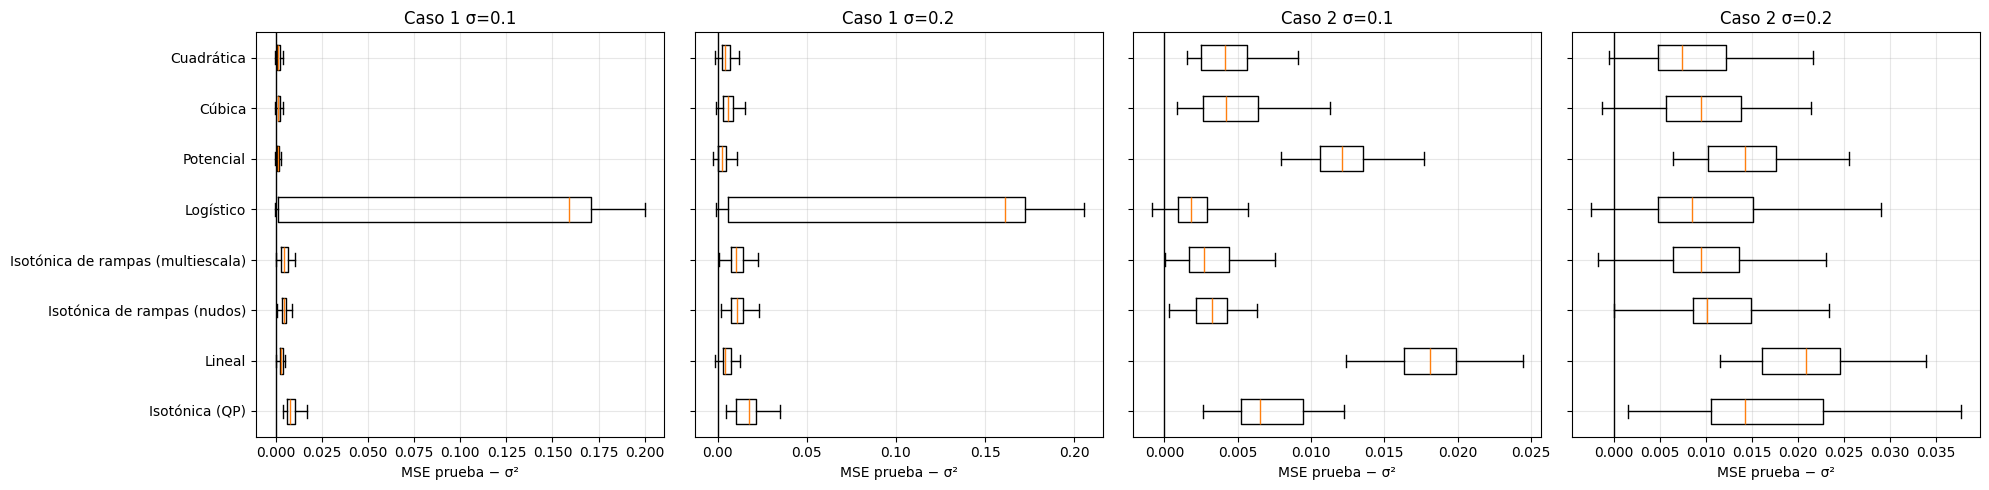

In [119]:
# %% Celda 7 — Ranking de PREDICCIÓN con datos nuevos de las mismas fórmulas
#-- Idea: ajustar con un grupo de datos (entrenamiento) y medir el error
#-- con OTRO grupo nuevo, generado con la misma fórmula y el mismo ruido
#-- (prueba). El modelo nunca ha visto los datos de prueba.
#-- Se repite muchas veces para que el ranking no dependa de la suerte.
#--
#-- Reutiliza: generar_datos_caso1, generar_datos_caso2, MODELOS
#-- (celda 5) y las librerías importadas en la celda 1.

import warnings
from scipy.optimize import OptimizeWarning


@dataclass
class Experimento:
    """Una fórmula + un nivel de ruido. Sabe generar datos nuevos."""
    nombre: str
    generador: object
    sigma: float

    def generar(
            self,
            n,
            ):
        return self.generador(n=n, sigma=self.sigma)


EXPERIMENTOS = [
    Experimento("Caso 1 σ=0.1", generar_datos_caso1, 0.1),
    Experimento("Caso 1 σ=0.2", generar_datos_caso1, 0.2),
    Experimento("Caso 2 σ=0.1", generar_datos_caso2, 0.1),
    Experimento("Caso 2 σ=0.2", generar_datos_caso2, 0.2),
    ]


def error_de_prediccion(
        ajustar,
        entrenamiento,
        prueba,
        ):
    """Ajusta con 'entrenamiento' y mide el MSE sobre 'prueba'.
    Devuelve NaN si el modelo falla o predice valores no finitos."""
    x_entrenamiento, y_entrenamiento = entrenamiento
    x_prueba, y_prueba = prueba

    try:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore", OptimizeWarning)
            #-- curve_fit avisa cuando no puede estimar la incertidumbre
            #-- de los parámetros. No nos importa aquí: solo predecimos.
            predecir = ajustar(x_entrenamiento, y_entrenamiento)
            prediccion = predecir(x_prueba)
    except (RuntimeError, ValueError, np.linalg.LinAlgError):
        return np.nan

    if not np.all(np.isfinite(prediccion)):
        return np.nan
    return np.mean((prediccion - y_prueba) ** 2)


def una_repeticion(
        experimento,
        modelos,
        n_entrenamiento,
        n_prueba,
        ):
    """Un grupo de entrenamiento y un grupo de prueba nuevos.
    Todos los modelos reciben exactamente los mismos datos."""
    entrenamiento = experimento.generar(n_entrenamiento)
    prueba = experimento.generar(n_prueba)

    errores = {}
    for nombre, ajustar in modelos.items():
        errores[nombre] = error_de_prediccion(ajustar, entrenamiento, prueba)
    return errores


def ejecutar_ranking_de_prediccion(
        experimentos,
        modelos,
        repeticiones=50,
        n_entrenamiento=25,
        n_prueba=500,
        semilla=2026,
        ):
    """Devuelve una tabla larga: una fila por (repetición, escenario, modelo)."""
    np.random.seed(semilla)
    #-- Tus generadores usan el estado aleatorio global de numpy.
    #-- Fijarlo aquí hace que toda la celda sea reproducible.

    registros = []
    for repeticion in range(repeticiones):
        for experimento in experimentos:
            errores = una_repeticion(
                experimento,
                modelos,
                n_entrenamiento,
                n_prueba,
                )
            for modelo, error in errores.items():
                registros.append({
                    "repeticion": repeticion,
                    "escenario": experimento.nombre,
                    "modelo": modelo,
                    "mse": error,
                    "ruido": experimento.sigma ** 2,
                    })

    tabla = pd.DataFrame(registros)
    tabla["exceso"] = tabla["mse"] - tabla["ruido"]
    #-- El ruido σ² no lo puede predecir nadie: es el suelo del error.
    #-- 'exceso' es lo que el modelo añade por encima de ese suelo.
    return tabla


def anadir_rangos(
        registros,
        ):
    """Rango de cada modelo DENTRO de cada (repetición, escenario).
    1 = mejor. Un modelo que falla recibe el peor rango."""
    grupos = registros.groupby(["repeticion", "escenario"])["mse"]
    registros = registros.copy()
    registros["rango"] = grupos.rank(method="average", na_option="bottom")
    return registros


def resumir_ranking_de_prediccion(
        registros,
        experimentos,
        ):
    orden_escenarios = [experimento.nombre for experimento in experimentos]

    rangos_por_escenario = registros.pivot_table(
        index="modelo",
        columns="escenario",
        values="rango",
        aggfunc="mean",
        )[orden_escenarios]

    resumen = rangos_por_escenario.copy()
    resumen["Ranking Medio"] = registros.groupby("modelo")["rango"].mean()
    resumen["Victorias (%)"] = registros.groupby("modelo")["rango"].apply(
        lambda rangos: 100 * np.mean(rangos == 1),
        )
    resumen["MSE prueba medio"] = registros.groupby("modelo")["mse"].mean()
    resumen["Exceso sobre σ²"] = registros.groupby("modelo")["exceso"].mean()
    resumen["Fallos"] = registros.groupby("modelo")["mse"].apply(
        lambda errores: int(errores.isna().sum()),
        )
    return resumen.sort_values(by="Ranking Medio")


def dibujar_distribucion_de_errores(
        registros,
        experimentos,
        orden_modelos,
        ):
    """Una caja por modelo: cómo varía el exceso de error entre repeticiones.
    Cajas estrechas y bajas = modelo fiable."""
    figura, ejes = plt.subplots(
        1,
        len(experimentos),
        figsize=(5 * len(experimentos), 5),
        sharey=False,
        )
    for eje, experimento in zip(ejes, experimentos):
        datos_escenario = registros[registros["escenario"] == experimento.nombre]
        valores = [
            datos_escenario.loc[datos_escenario["modelo"] == modelo, "exceso"].dropna()
            for modelo in orden_modelos
            ]
        posiciones = np.arange(1, len(orden_modelos) + 1)
        eje.boxplot(valores, positions=posiciones, vert=False, showfliers=False)
        eje.set_yticks(posiciones)
        eje.set_yticklabels(orden_modelos)
        #-- Etiquetas puestas a mano: el nombre del argumento 'labels'
        #-- de boxplot cambia entre versiones de matplotlib.
        eje.invert_yaxis()
        #-- El mejor modelo del ranking queda arriba.
        eje.axvline(0, color="black", linewidth=1)
        eje.set_title(experimento.nombre)
        eje.set_xlabel("MSE prueba − σ²")
        eje.grid(True, alpha=0.3)
    for eje in ejes[1:]:
        eje.set_yticklabels([])
    plt.tight_layout()
    plt.show()


# -- Ejecutar ---------------------------------------------------------
registros_prediccion = ejecutar_ranking_de_prediccion(
    EXPERIMENTOS,
    MODELOS,
    repeticiones=50,
    n_entrenamiento=25,
    n_prueba=500,
    )
registros_prediccion = anadir_rangos(registros_prediccion)

ranking_prediccion = resumir_ranking_de_prediccion(
    registros_prediccion,
    EXPERIMENTOS,
    )

print("Ranking de PREDICCIÓN (datos nuevos, 50 repeticiones):")
display(ranking_prediccion.round(4))

dibujar_distribucion_de_errores(
    registros_prediccion,
    EXPERIMENTOS,
    list(ranking_prediccion.index),
    )

Generalizar para x1 x2 y y